# Quark vs gluon DTMD

Ratio of the $K_\perp$-integrated quark and gluon DTMDs of the diffractive$_\text{TMD}$ cross section, without the hard factors $\mathcal H$ and $\mathcal H'$, computed directly from the formulas of the manuscript (not from `src/integrands.cpp`). Proton target, $p_\perp=8$ GeV, $z=1/2$. The common prefactor $S_\perp/(8\pi^4)$ cancels in the ratio.

$$\text{gluon}=\int d^2K\,\frac{N_c^2-1}{1-x}\,G^2,\qquad G=\Omega^2\int dR\,R\,J_2(KR)K_2(\Omega R)\,\mathcal N_g,\qquad \Omega^2=\frac{xK^2}{1-x}$$

$$\text{quark}=\int d^2K\,N_c\frac{x}{1-x}\frac{K^2+m^2}{xK^2+m^2}\Big[\tilde{\mathcal Q}_1^2+\frac{(1-x)m^2}{xK^2+m^2}\tilde{\mathcal Q}_0^2\Big],\qquad \tilde{\mathcal Q}_n=\tilde\Omega^2\int dR\,R\,J_n(KR)K_n(\tilde\Omega R)\,\mathcal N,\qquad \tilde\Omega^2=\frac{m^2+xK^2}{1-x}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, kv

Nc, CF = 3, 4 / 3
p, z, sqrt_s = 8.0, 0.5, 5360.0

Proton dipole amplitude (BK solution). The file has 4 header values (`###`) and then, for each rapidity $Y=\ln(0.01/x_{\mathbb P})$, a `###` line with $Y$ followed by $N(r)$.

In [2]:
chunks = open("../data/proton/mve.dat").read().split("###")[1:]
rmin, mult, nr, x0 = (float(c) for c in chunks[:4])
r_grid = rmin * mult ** np.arange(int(nr))
Y_grid = np.array([float(c.split()[0]) for c in chunks[4:]])
N_grid = np.array([np.array(c.split()[1:], float) for c in chunks[4:]])

def dipole(x_po, R):
    """N(R) at x_po (frozen at the initial condition for x_po > 0.01)"""
    Y = max(0, np.log(x0 / x_po))
    N = N_grid[np.argmin(abs(Y_grid - Y))]
    return np.interp(np.log(R), np.log(r_grid), N, left=0, right=1)

Radial integrals and the $K_\perp$-integrated terms (cuts of the manuscript: $K\leq2m_T$ for the gluon, $K\leq2p_\perp$ for the quark).

In [3]:
def radial(n, k, omega, N):
    """omega^2 int dR R J_n(kR) K_n(omega R) N(R)"""
    rmax = min(100, 40 / omega)                     # K_n(omega R) is negligible beyond
    R = np.linspace(1e-6, rmax, 400 + int(20 * k * rmax))   # enough points for the oscillations of J_n
    return omega**2 * np.trapz(R * jv(n, k * R) * kv(n, omega * R) * N(R), R)

K = np.geomspace(0.01, 2 * np.sqrt(p**2 + 1.5**2), 60)

def gluon(x, x_po, m):
    """int d2K of the gluon DTMD"""
    Ng = lambda R: 2 * dipole(x_po, R) - dipole(x_po, R) ** 2
    mt = np.sqrt(p**2 + m**2)
    Kg = K[K <= 2 * mt]
    G2 = np.array([radial(2, k, np.sqrt(x / (1 - x)) * k, Ng) ** 2 for k in Kg])
    return np.trapz(2 * np.pi * Kg * (Nc**2 - 1) / (1 - x) * G2, Kg)

def quark(x, x_po, m):
    """int d2K of the quark DTMD"""
    N = lambda R: dipole(x_po, R)
    Kq = K[K <= 2 * p]
    vals = []
    for k in Kq:
        omega = np.sqrt((m**2 + x * k**2) / (1 - x))
        a = x * k**2 + m**2
        Q1, Q0 = radial(1, k, omega, N), radial(0, k, omega, N)
        vals.append(Nc * x / (1 - x) * (k**2 + m**2) / a * (Q1**2 + (1 - x) * m**2 / a * Q0**2))
    return np.trapz(2 * np.pi * Kq * np.array(vals), Kq)

def hard_factor_ratio(m):
    """H'/H, for reference (not included in the plot)"""
    H = z * ((z**2 + (1 - z)**2) * (p**4 + m**4) + 2 * m**2 * p**2) / (p**2 + m**2) ** 4
    H_quark = 2 * CF * z * z * (1 + (1 - z)**2) / p**4
    return H_quark / H

Quark/gluon DTMD ratio for charm ($m=1.5$ GeV) and an almost massless quark, at the rapidities of Fig. 4. At each $x_{\mathbb P}$, the gluon term uses $x_g=M_{q\bar q}^2/(x_{\mathbb P}W^2)$ with $M_{q\bar q}^2=m_T^2/[z(1-z)]$, and the quark term $x_q=M_{qg}^2/(x_{\mathbb P}W^2)$ with $M_{qg}^2=p_\perp^2/[z(1-z)]+m^2/z$, where $W^2=\sqrt2\sqrt{s}\,q^+=2m_T\sqrt{s}\,e^y$. The $x_{\mathbb P}$ values are those where $x_g=0.9,\dots,0.05$. A few seconds.

In [4]:
x_values = np.array([0.9, 0.7, 0.5, 0.3, 0.1, 0.05])
masses, rapidities = [1.5, 0.05], [0, 1, 2]
x_po, ratio = {}, {}
for m in masses:
    mt = np.sqrt(p**2 + m**2)
    for y in rapidities:
        W2 = 2 * mt * sqrt_s * np.exp(y)
        M2_qq = (p**2 + m**2) / (z * (1 - z))      # hard pair of the gluon term
        M2_qg = p**2 / (z * (1 - z)) + m**2 / z    # hard pair of the quark term
        x_po[m, y] = M2_qq / (x_values * W2)
        x_q = M2_qg / (x_po[m, y] * W2)
        ratio[m, y] = [quark(xq, xp, m) / gluon(xg, xp, m) for xg, xq, xp in zip(x_values, x_q, x_po[m, y])]
        print(f"m = {m} GeV, y = {y}  (H'/H = {hard_factor_ratio(m):.2f})")
        for x, xq, xp, r in zip(x_values, x_q, x_po[m, y], ratio[m, y]):
            print(f"   x_g = {x:4.2f}   x_q = {xq:4.2f}   x_P = {xp:.1e}   quark/gluon DTMD = {r:.3f}   with H'/H = {r * hard_factor_ratio(m):.3f}")

m = 1.5 GeV, y = 0  (H'/H = 3.35)
   x_g = 0.90   x_q = 0.88   x_P = 3.4e-03   quark/gluon DTMD = 0.036   with H'/H = 0.122
   x_g = 0.70   x_q = 0.69   x_P = 4.3e-03   quark/gluon DTMD = 0.015   with H'/H = 0.049
   x_g = 0.50   x_q = 0.49   x_P = 6.1e-03   quark/gluon DTMD = 0.006   with H'/H = 0.022
   x_g = 0.30   x_q = 0.29   x_P = 1.0e-02   quark/gluon DTMD = 0.002   with H'/H = 0.008
   x_g = 0.10   x_q = 0.10   x_P = 3.0e-02   quark/gluon DTMD = 0.001   with H'/H = 0.002
   x_g = 0.05   x_q = 0.05   x_P = 6.1e-02   quark/gluon DTMD = 0.000   with H'/H = 0.001
m = 1.5 GeV, y = 1  (H'/H = 3.35)
   x_g = 0.90   x_q = 0.88   x_P = 1.2e-03   quark/gluon DTMD = 0.057   with H'/H = 0.192
   x_g = 0.70   x_q = 0.69   x_P = 1.6e-03   quark/gluon DTMD = 0.022   with H'/H = 0.073
   x_g = 0.50   x_q = 0.49   x_P = 2.2e-03   quark/gluon DTMD = 0.010   with H'/H = 0.032
   x_g = 0.30   x_q = 0.29   x_P = 3.7e-03   quark/gluon DTMD = 0.004   with H'/H = 0.012
   x_g = 0.10   x_q = 0.10   x_P

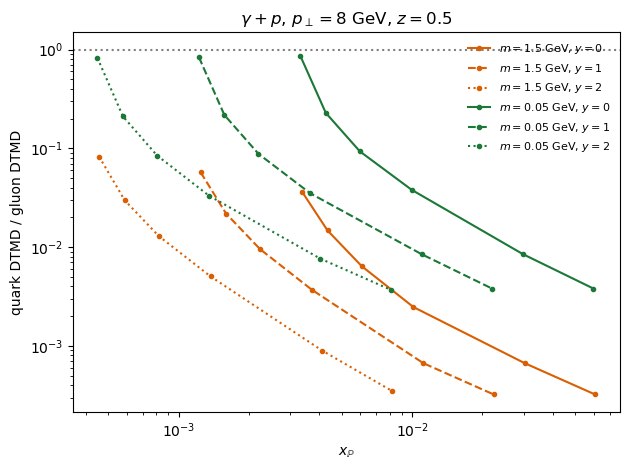

In [5]:
colors = {1.5: "#d95f02", 0.05: "#1b7837"}
labels = {1.5: "$m=1.5$ GeV", 0.05: "$m=0.05$ GeV"}
styles = {0: "-", 1: "--", 2: ":"}
for (m, y), r in ratio.items():
    plt.plot(x_po[m, y], r, color=colors[m], ls=styles[y], marker="o", ms=3,
             label=f"{labels[m]}, $y={y}$")
plt.axhline(1, color="0.5", ls=":")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$x_{\mathbb{P}}$")
plt.ylabel("quark DTMD / gluon DTMD")
plt.title(rf"$\gamma+p$, $p_\perp={p:g}$ GeV, $z=0.5$")
plt.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("../plots/quark_gluon_dtmd_ratio.pdf", bbox_inches="tight")
plt.show()

**Result.** For a massless quark the two DTMDs are comparable close to $x_{\mathbb P\min}$ ($x\to1$), as found for light quarks in DIS (arXiv:2510.24171). For charm, $\tilde\Omega\geq m$ restricts the semi-hard antiquark to small dipoles $R_\perp\lesssim1/m$, which scatter weakly, and the quark DTMD is more than an order of magnitude smaller. In the cross section, the hard factors add $\mathcal H'/\mathcal H\approx3.3$ at $z=1/2$.